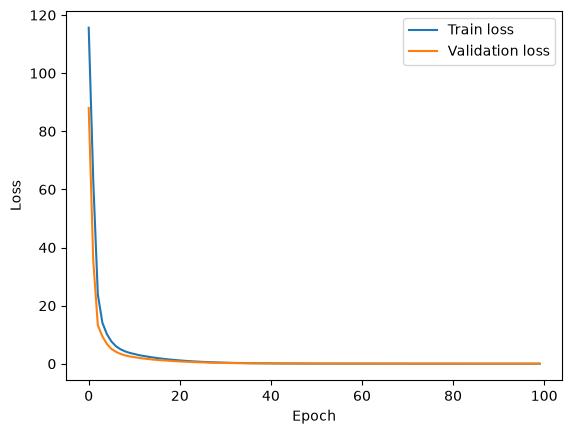

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
MAE: 25686
R2: 0.759


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, r2_score

d = np.load("../data/processed/data.npz")
X_train, X_val = d["X_train"], d["X_val"]
y_train, y_val = d["y_train"], d["y_val"]

model = keras.Sequential([
    layers.Input(shape=(6,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])
model.compile(optimizer="adam", loss="mse")

history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=100, batch_size=32, verbose=0)

# Learning curve
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

# Score
pred = np.expm1(model.predict(X_val).flatten())
true = np.expm1(y_val)
print("MAE:", round(mean_absolute_error(true, pred)))
print("R2:", round(r2_score(true, pred), 3))

Ruk gaya epoch par: 262


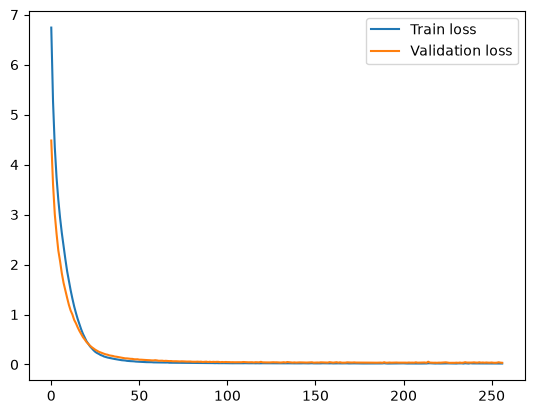

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
MAE: 20490
R2: 0.867


In [2]:
from tensorflow.keras.callbacks import EarlyStopping

model2 = keras.Sequential([
    layers.Input(shape=(6,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])
model2.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")

es = EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)
history2 = model2.fit(X_train, y_train,
                      validation_data=(X_val, y_val),
                      epochs=500, batch_size=32, callbacks=[es], verbose=0)

print("Ruk gaya epoch par:", len(history2.history["loss"]))

plt.plot(history2.history["loss"][5:], label="Train loss")
plt.plot(history2.history["val_loss"][5:], label="Validation loss")
plt.legend(); plt.show()

pred = np.expm1(model2.predict(X_val).flatten())
true = np.expm1(y_val)
print("MAE:", round(mean_absolute_error(true, pred)))
print("R2:", round(r2_score(true, pred), 3))